# Workshop 3 — Feature engineering and training

**Goal:** select and prepare the features, train a simple regression model, evaluate it
and serialize it in `models/model.pkl` as a scikit-learn **`Pipeline`** (preprocessing + model).

**Outputs**

| File | Content |
|---|---|
| `models/model.pkl` | Trained pipeline (`StandardScaler` + model) |
| `models/metrics.json` | Evaluation metrics |
| `data/streaming/streaming_events.csv` | Records of the 30 % test set: what the *producer* will send to Kafka |

> The focus of the workshop is **pipeline integration**, not maximizing model accuracy.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Configuration shared with the producer/consumer (feature order, paths...)
sys.path.append("../kafka")
from settings import FEATURES, MODEL_PATH, STREAMING_FILE, TARGET_FIELD

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("../data/processed/happiness_unified.csv")
print("Dataset:", df.shape)
print("Features of the event contract:", FEATURES)
df.head()

Dataset: (782, 10)
Features of the event contract: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption
0,Afghanistan,Southern Asia,2015,3.575,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719
1,Albania,Central and Eastern Europe,2015,4.959,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413
2,Algeria,Middle East and Northern Africa,2015,5.605,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383
3,Angola,Sub-Saharan Africa,2015,4.033,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122
4,Argentina,Latin America and Caribbean,2015,6.574,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484


## 3. Feature engineering

### 3.1 Descriptive statistics

In [2]:
df[["happiness_score"] + FEATURES].describe().round(3)

,happiness_score,gdp,family,health,freedom,generosity,corruption
count,782.000,782.000,782.000,782.000,782.000,782.000,782.000
mean,5.379,0.916,1.078,0.612,0.411,0.219,0.126
std,1.127,0.407,0.330,0.248,0.153,0.122,0.106
min,2.693,0.000,0.000,0.000,0.000,0.000,0.000
25%,4.510,0.606,0.869,0.440,0.310,0.130,0.054
50%,5.322,0.982,1.125,0.647,0.431,0.202,0.091
75%,6.190,1.236,1.327,0.808,0.531,0.279,0.156
max,7.769,2.096,1.644,1.141,0.724,0.838,0.552


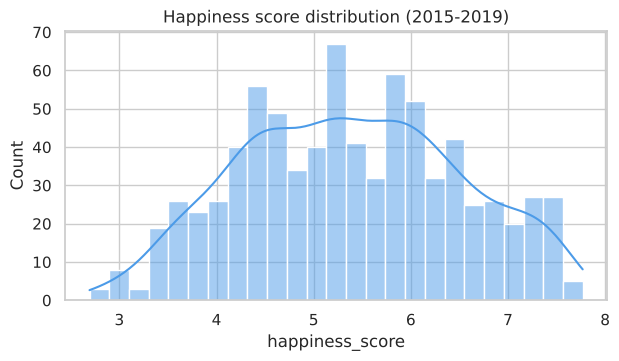

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["happiness_score"], bins=25, kde=True, ax=ax, color="#4c9be8")
ax.set_title("Happiness score distribution (2015-2019)")
plt.show()

### 3.2 Relationships among variables

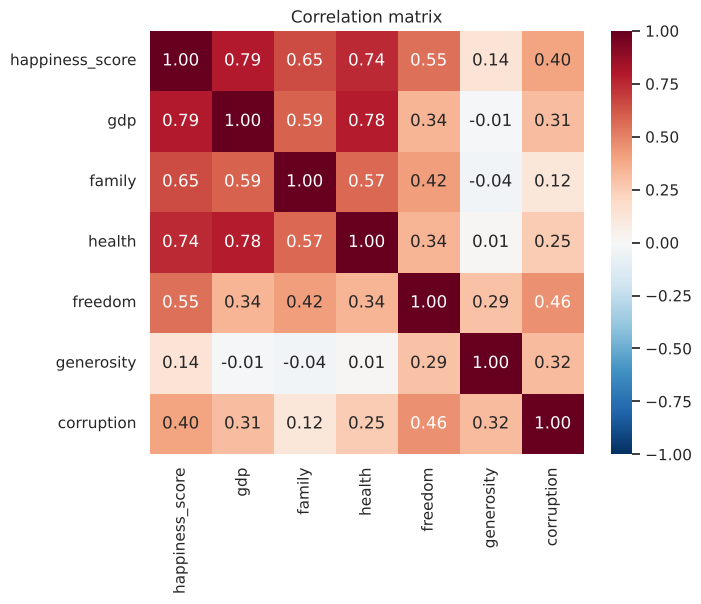

,corr_with_score
gdp,0.789
health,0.742
family,0.649
freedom,0.551
corruption,0.400
generosity,0.138


In [4]:
corr = df[["happiness_score"] + FEATURES].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

corr["happiness_score"].drop("happiness_score").sort_values(ascending=False).round(3).to_frame("corr_with_score")

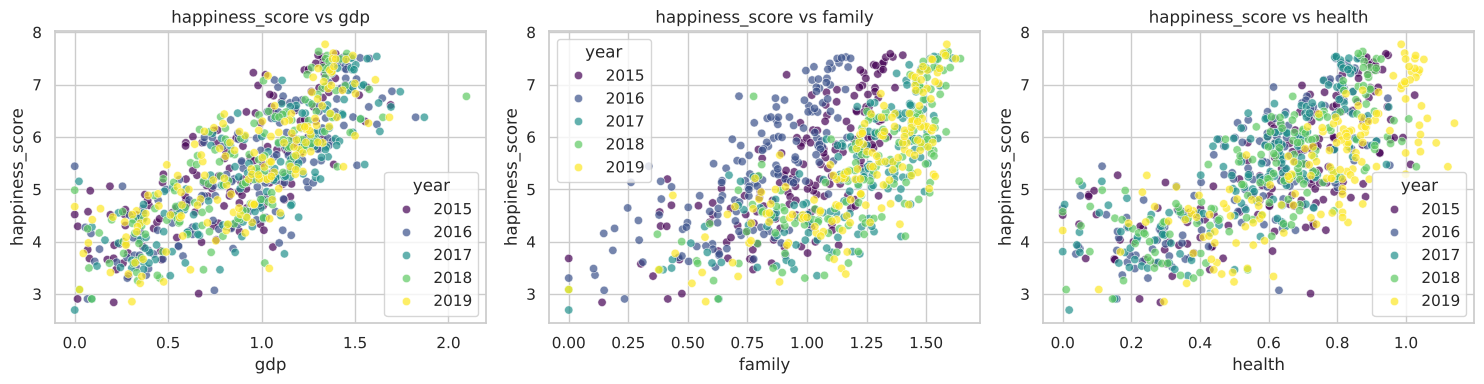

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["gdp", "family", "health"]):
    sns.scatterplot(data=df, x=col, y="happiness_score", hue="year", palette="viridis", alpha=0.7, ax=ax)
    ax.set_title(f"happiness_score vs {col}")
plt.tight_layout()
plt.show()

### 3.3 Feature selection (and justification)

**Selected features (6):** `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`.

- **They are the ones in the event contract.** The consumer only receives these 6 fields in each event, so the model
  must be able to predict with exactly them and in this order (that is why the order comes from `settings.py`).
- **They make business sense and have statistical signal.** `gdp` (0.79), `health` (0.74) and `family` (0.65) are the
  most correlated with the score; `freedom` (0.55) and `corruption` (0.40) add moderate signal;
  `generosity` (0.14) is weak but is kept because it is part of the contract and does not hurt the model.
- **Multicollinearity:** `gdp` and `health` are strongly related to each other (≈0.78). Neither is removed because
  the goal is not to interpret coefficients and the model remains stable.

**Avoiding *target leakage*:** rank, `Standard Error`, confidence intervals, `Whisker.*` and
`Dystopia Residual` are excluded (derived from the score; already dropped in the EDA). `actual_happiness_score` is **only** used as
*target* and to measure the error: it is never a feature.

**Categorical variables:** `country` and `region` are **not used as features**. Encoding ~164 countries (one-hot) would
overfit to the country identity and, besides, `region` does not travel in the event, so the consumer could not
compute it. That is why no encoder is needed.
`year` is not used either: it is an identifier of the observation, not a characteristic of the country.

**Scaling:** the 6 features are on similar scales (0-2) but `StandardScaler` is applied inside the Pipeline
so that the preprocessing is serialized together with the model and the consumer applies exactly the same.

In [6]:
LEAKAGE_COLUMNS = ["happiness_score", "rank", "standard_error", "dystopia_residual"]
assert "happiness_score" not in FEATURES and TARGET_FIELD not in FEATURES, "The target cannot be a feature"
assert not set(FEATURES) & set(LEAKAGE_COLUMNS)

X = df[FEATURES]            # same order as the event contract
y = df["happiness_score"]
print("X:", X.shape, "| y:", y.shape)

X: (782, 6) | y: (782,)


## 4. Regression model training

### 4.1 70 % training / 30 % test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print(f"Train: {len(X_train)} rows ({len(X_train)/len(X):.0%}) | Test: {len(X_test)} rows ({len(X_test)/len(X):.0%})")

Train: 547 rows (70%) | Test: 235 rows (30%)


### 4.2 Candidates and selection
Two of the suggested models are compared. Each one is a `Pipeline` with the same preprocessing.
The selection is made with **5-fold cross-validation on the training set** (so the test set stays
untouched for the final evaluation).

In [8]:
candidates = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "RandomForestRegressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(n_estimators=100, random_state=42)),
    ]),
}

cv_results = {}
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    cv_results[name] = -scores.mean()

cv_table = pd.Series(cv_results, name="CV_RMSE (train)").round(4).to_frame()
best_name = cv_table["CV_RMSE (train)"].idxmin()
print("Selected model:", best_name)
cv_table

Selected model: RandomForestRegressor


,CV_RMSE (train)
LinearRegression,0.5505
RandomForestRegressor,0.5062


### 4.3 Train and evaluate on the test set

In [9]:
def evaluate(pipe, X_, y_):
    pred = pipe.predict(X_)
    return {
        "MAE": mean_absolute_error(y_, pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_, pred))),
        "R2": r2_score(y_, pred),
    }

rows = {}
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    rows[f"{name} - train"] = evaluate(pipe, X_train, y_train)
    rows[f"{name} - test"] = evaluate(pipe, X_test, y_test)

pd.DataFrame(rows).T.round(4)

,MAE,RMSE,R2
LinearRegression - train,0.4245,0.5454,0.7647
LinearRegression - test,0.4289,0.5538,0.7599
RandomForestRegressor - train,0.1418,0.1862,0.9726
RandomForestRegressor - test,0.3983,0.5086,0.7976


In [10]:
model = candidates[best_name]
metrics = evaluate(model, X_test, y_test)
print(f"Final model: {best_name}")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}")

Final model: RandomForestRegressor
  MAE: 0.3983
  RMSE: 0.5086
  R2: 0.7976


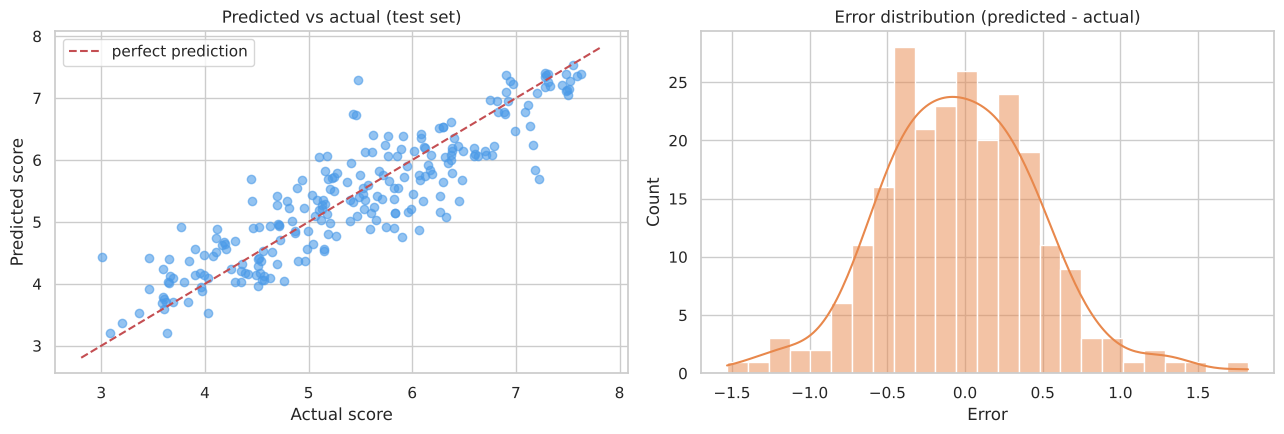

In [11]:
pred_test = model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(y_test, pred_test, alpha=0.6, color="#4c9be8")
lims = [y_test.min() - 0.2, y_test.max() + 0.2]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual score")
axes[0].set_ylabel("Predicted score")
axes[0].set_title("Predicted vs actual (test set)")
axes[0].legend()

sns.histplot(pred_test - y_test, bins=25, kde=True, ax=axes[1], color="#e8884c")
axes[1].set_title("Error distribution (predicted - actual)")
axes[1].set_xlabel("Error")

plt.tight_layout()
plt.show()

In [12]:
# Interpretability (coefficients if the final model is linear, importances otherwise)
if best_name == "LinearRegression":
    coefs = pd.Series(model.named_steps["model"].coef_, index=FEATURES, name="coefficient (standardized features)")
    display(coefs.round(3).sort_values(ascending=False).to_frame())
else:
    imp = pd.Series(model.named_steps["model"].feature_importances_, index=FEATURES, name="importance")
    display(imp.round(3).sort_values(ascending=False).to_frame())

,importance
gdp,0.463
health,0.266
freedom,0.099
family,0.062
corruption,0.059
generosity,0.052


### 4.4 Save the model and the streaming data

- `models/model.pkl` contains the **complete Pipeline** (scaling + model). The consumer only calls
  `model.predict(...)` with a DataFrame with the 6 columns in the same order.
- `data/streaming/streaming_events.csv` contains **the 30 % test set** (records the model has never seen):
  this way the error shown in the dashboard is an honest measure of generalization.
  It is sorted by year to simulate data arriving "over time".

In [13]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_PATH)

metrics_out = {
    "model": best_name,
    "features": FEATURES,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "MAE": round(metrics["MAE"], 4),
    "RMSE": round(metrics["RMSE"], 4),
    "R2": round(metrics["R2"], 4),
    "scikit_learn_version": sklearn.__version__,
}
(MODEL_PATH.parent / "metrics.json").write_text(json.dumps(metrics_out, indent=2))

# Test records that the producer will send
streaming = (
    df.loc[X_test.index, ["country", "year"] + FEATURES + ["happiness_score"]]
    .rename(columns={"happiness_score": TARGET_FIELD})
    .sort_values(["year", "country"])
    .reset_index(drop=True)
)
STREAMING_FILE.parent.mkdir(parents=True, exist_ok=True)
streaming.to_csv(STREAMING_FILE, index=False)

print("Model saved at:", MODEL_PATH)
print("Events for streaming:", len(streaming))
streaming.head()

Model saved at: /home/claude/project/models/model.pkl
Events for streaming: 235


,country,year,gdp,family,health,freedom,generosity,corruption,actual_happiness_score
0,Algeria,2015,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,5.605
1,Australia,2015,1.33358,1.30923,0.93156,0.65124,0.43562,0.35637,7.284
2,Austria,2015,1.33723,1.29704,0.89042,0.62433,0.33088,0.18676,7.200
3,Bangladesh,2015,0.39753,0.43106,0.60164,0.40820,0.21222,0.12569,4.694
4,Cameroon,2015,0.42250,0.88767,0.23402,0.49309,0.20618,0.05786,4.252


### 4.5 Verification: load `model.pkl` and predict the way the consumer will

In [14]:
loaded = joblib.load(MODEL_PATH)

assert list(loaded.feature_names_in_) == FEATURES, "The model does not match the contract"

sample = streaming.iloc[[0]]
X_sample = sample[FEATURES]                      # same column order
print("Country:", sample["country"].iloc[0], "| year:", sample["year"].iloc[0])
print("Actual score:   ", float(sample[TARGET_FIELD].iloc[0]))
print("Predicted score:", round(float(loaded.predict(X_sample)[0]), 3))

# The reloaded model must give exactly the same predictions
assert np.allclose(loaded.predict(X_test), model.predict(X_test))
print("OK: model.pkl reproduces the predictions of the trained model")

Country: Algeria | year: 2015
Actual score:    5.605
Predicted score: 5.148
OK: model.pkl reproduces the predictions of the trained model


### Summary
- 6 contract features, no target leakage, no categorical variables.
- 70/30 split (`random_state=42`), selection by CV on train, evaluation on test.
- `model.pkl` = `Pipeline(StandardScaler → model)`; `metrics.json` with MAE, RMSE and R².
- `streaming_events.csv` = test records ready for the producer.